# 03 – Financial values and outliers (task A3)
Financial amounts (income, loan size, balances, limits) are heavily right-skewed, and
ratios (DTI, utilization) have values outside their usual range. For each field we
profile the distribution, test whether mean ± 3 standard deviations is a sound outlier
rule, choose and justify a treatment, and show its effect on the distribution and on the
default rate. All statistics that will be reused (caps, percentiles) are computed only on
loans issued up to 31 Dec 2014, the fit cutoff, so 2015 data never influences them.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

train = pd.read_parquet(Path("../data/interim/train_audited.parquet"))
FIT_CUTOFF = pd.Timestamp("2014-12-31")
fit = train[train["issue_dt"] <= FIT_CUTOFF].copy()

AMOUNTS = ["annual_inc", "loan_amnt", "installment", "revol_bal", "tot_cur_bal",
           "avg_cur_bal", "total_rev_hi_lim", "tot_hi_cred_lim"]
RATIOS = ["dti", "revol_util", "bc_util"]
FIN_COLS = AMOUNTS + RATIOS

print("all training loans:", len(train), "| fit sample (≤ 2014):", len(fit))

all training loans: 30000 | fit sample (≤ 2014): 14373


In [2]:
def profile(df, cols):
    """Distribution summary for each column: centre, spread, shape and tails."""
    rows = {}
    for c in cols:
        s = df[c]
        q = s.quantile([0.01, 0.05, 0.25, 0.5, 0.75, 0.95, 0.99])
        rows[c] = {
            "mean": s.mean(), "median": s.median(), "std": s.std(),
            "IQR": q[0.75] - q[0.25], "skew": s.skew(),
            "min": s.min(), "p1": q[0.01], "p5": q[0.05], "p25": q[0.25], "p50": q[0.5],
            "p75": q[0.75], "p95": q[0.95], "p99": q[0.99], "max": s.max(),
            "zeros": int((s == 0).sum()), "missing": int(s.isna().sum()),
        }
    return pd.DataFrame(rows).T

prof = profile(fit, FIN_COLS)
pd.set_option("display.float_format", "{:,.2f}".format)
display(prof)

,mean,median,std,IQR,skew,min,p1,p5,p25,p50,p75,p95,p99,max,zeros,missing
annual_inc,"74,374.27","64,900.00","76,972.56","45,000.00",63.33,"7,500.00","19,620.24","29,000.00","45,000.00","64,900.00","90,000.00","150,000.00","250,000.00","7,500,000.00",0.00,0.00
loan_amnt,"14,635.75","12,975.00","8,328.14","12,000.00",0.71,"1,000.00","1,736.00","3,700.00","8,000.00","12,975.00","20,000.00","31,100.00","35,000.00","35,000.00",0.00,0.00
installment,444.82,388.11,246.41,314.46,0.93,23.26,59.24,125.88,268.60,388.11,583.06,931.19,"1,195.88","1,406.45",0.00,0.00
revol_bal,"17,736.00","12,113.00","27,646.68","14,227.00",12.82,0.00,557.72,"2,398.80","6,568.00","12,113.00","20,795.00","43,408.80","115,303.04","1,181,030.00",40.00,0.00
tot_cur_bal,"138,834.12","80,428.00","152,176.33","181,986.00",2.89,0.00,"3,309.88","8,506.40","28,460.00","80,428.00","210,446.00","418,800.60","631,213.16","3,370,799.00",3.00,0.00
avg_cur_bal,"13,446.81","7,554.00","16,086.65","15,954.00",4.76,0.00,505.44,"1,102.60","3,010.00","7,554.00","18,964.00","42,195.80","70,493.68","497,484.00",3.00,0.00
total_rev_hi_lim,"30,462.54","22,800.00","30,178.17","24,200.00",5.74,0.00,"3,000.00","6,000.00","13,500.00","22,800.00","37,700.00","78,140.00","141,140.00","903,300.00",2.00,0.00
tot_hi_cred_lim,"168,292.66","108,719.00","167,893.13","199,405.00",2.67,300.00,"8,100.00","17,100.00","46,475.00","108,719.00","245,880.00","477,397.60","724,280.76","3,492,496.00",0.00,0.00
dti,17.67,17.23,7.94,11.70,0.19,0.00,2.22,5.12,11.70,17.23,23.40,31.41,34.87,39.97,5.00,0.00
revol_util,56.29,57.00,23.07,34.00,-0.04,0.00,3.67,16.34,40.00,57.00,74.00,92.00,98.00,366.60,49.00,4.00


### Distributions on linear and log scales
Each field is plotted twice. On the linear scale, a long right tail squeezes most loans
into a narrow spike near zero. On the log scale (log1p, so zeros are allowed), the same
data spreads out and becomes far more symmetric. The plots show which fields need a
log transform and where extreme values sit.

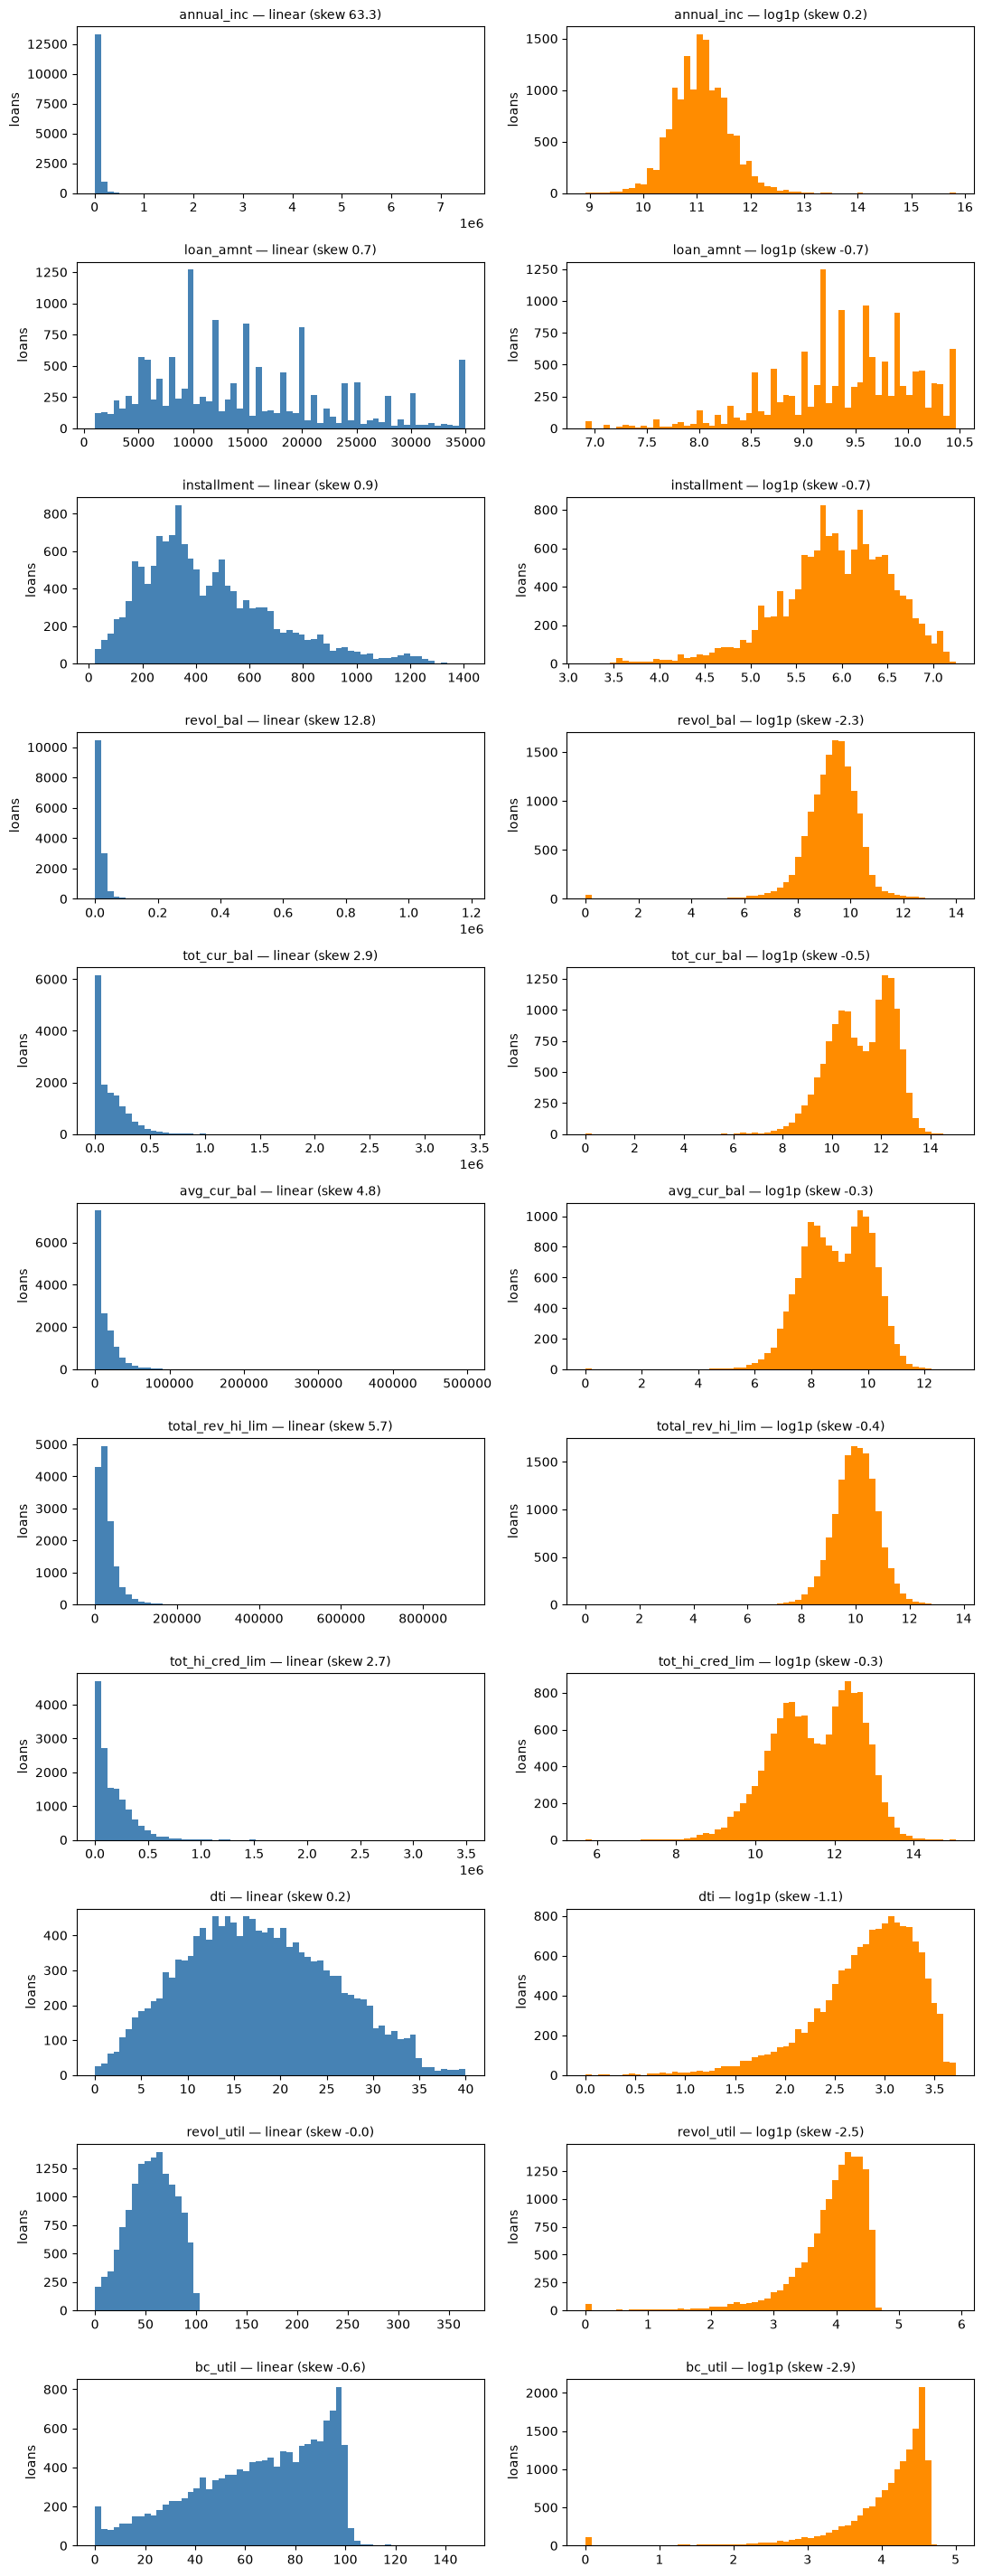

In [3]:
def plot_linear_vs_log(df, cols, path=None):
    """Two histograms per field: raw values (left) and log1p values (right)."""
    fig, axes = plt.subplots(len(cols), 2, figsize=(11, 2.6 * len(cols)))
    for row, c in zip(axes, cols):
        s = df[c].dropna()
        row[0].hist(s, bins=60, color="steelblue")
        row[0].set_title(f"{c} — linear (skew {s.skew():.1f})", fontsize=10)
        row[1].hist(np.log1p(s), bins=60, color="darkorange")
        row[1].set_title(f"{c} — log1p (skew {np.log1p(s).skew():.1f})", fontsize=10)
        for ax in row:
            ax.set_ylabel("loans")
    plt.tight_layout()
    if path:
        fig.savefig(path, dpi=120, bbox_inches="tight")
    plt.show()

plot_linear_vs_log(fit, FIN_COLS, path="../reports/financial_linear_vs_log.png")

### A3 Step 2: Linear vs log views

- **Money fields** (annual_inc, revol_bal, the balance and limit fields) are right-skewed across orders of magnitude, and log1p turns them into near-bell shapes (annual_inc skew 63.3 → 0.2). These get log1p plus an upper cap.
- revol_bal's post-log skew of −2.3 is caused by 40 zero balances sitting at log1p(0)=0. They are a separate group, flagged rather than treated as a tail.
- tot_cur_bal, avg_cur_bal and tot_hi_cred_lim are **bimodal** on the log scale, while revolving-only total_rev_hi_lim is not. Hypothesis: mortgage balances split homeowners from renters (checked below).
- **Bounded fields** (loan_amnt max 35,000 by policy, installment, dti stops at 40, revol_util, bc_util) are already roughly symmetric, and log1p over-corrects them into a left skew. They stay linear. dti and the utilisation fields get caps only.

In [5]:
def median_by_group(df, group_col, cols):
    """Median of each column per group, plus the group size."""
    out = df.groupby(group_col)[cols].median().round(0)
    out["loans"] = df[group_col].value_counts()
    return out.sort_values("loans", ascending=False)

median_by_group(fit, "home_ownership",
                ["tot_cur_bal", "avg_cur_bal", "tot_hi_cred_lim", "total_rev_hi_lim"])

,tot_cur_bal,avg_cur_bal,tot_hi_cred_lim,total_rev_hi_lim,loans
home_ownership,,,,,
MORTGAGE,"188,284.00","16,876.00","223,086.00","26,600.00",7407
RENT,"30,826.00","3,292.00","49,238.00","18,500.00",5560
OWN,"40,406.00","4,101.00","65,084.00","23,700.00",1406


### A3 Step 3: Why three balance fields are bimodal

On the log scale, tot_cur_bal, avg_cur_bal and tot_hi_cred_lim show two humps, while revolving-only total_rev_hi_lim shows one. Hypothesis: the mortgage-including fields mix borrowers with and without a mortgage.

Median by home_ownership (loans issued ≤ 2014):
- MORTGAGE vs RENT: tot_cur_bal 6.1×, avg_cur_bal 5.1×, tot_hi_cred_lim 4.5×, but total_rev_hi_lim only 1.4×.
- The MORTGAGE median ($188k, log ≈ 12.1) and the RENT median ($31k, log ≈ 10.3) sit on the two humps.
- OWN (no mortgage) is close to RENT ($40k), not MORTGAGE, so the driver is mortgage debt, not property ownership.

Conclusion: the humps are two populations, not a data error. A high total balance is normal for mortgage holders, so these fields should be read together with home_ownership. Expect them to load on a common factor in A6.

### A3 Step 4: Choosing the outlier method

Four rules compared on loans issued ≤ 2014 (upper limit and loans flagged):
- **Tukey IQR fence** flags 400–830 normal borrowers on right-skewed money fields (e.g. 616 incomes above $157,500; 428 tot_cur_bal values inside the mortgage hump). Too aggressive for long tails.
- **Mean ± 3 std** is distorted by the outliers it should detect (masking): the std is inflated by extreme incomes, and the lower limit for annual_inc is a negative income (−$156,545).
- **Percentile caps** always flag a fixed 1% / 0.5%. Good for long tails, but on bounded fields they cut real values (p99 dti = 34.9 would cap 143 loans inside the 40 policy limit).
- On symmetric bounded fields (dti, revol_util, bc_util) the IQR fence flags only 0–2 loans.

**Decision (all limits fitted on ≤ 2014, stored in data_spec.json):**
- Heavy-tailed money fields: log1p + cap at p99.5
- dti, revol_util, bc_util: cap at the IQR fence (40.9 / 125 / 150)
- loan_amnt, installment: no cap (bounded by lending policy; p99 = max = $35,000)

In [6]:
def compare_outlier_rules(df, cols):
    """For each field: upper limit and number of loans flagged under 4 common rules."""
    rows = []
    for c in cols:
        s = df[c].dropna()
        q1, q3 = s.quantile([0.25, 0.75])
        limits = {
            "mean+3std": s.mean() + 3 * s.std(),
            "iqr_fence": q3 + 1.5 * (q3 - q1),
            "p99": s.quantile(0.99),
            "p99.5": s.quantile(0.995),
        }
        for rule, upper in limits.items():
            rows.append({"field": c, "rule": rule, "upper": round(upper, 1),
                         "flagged": int((s > upper).sum())})
    table = pd.DataFrame(rows)
    return table.pivot(index="field", columns="rule", values=["upper", "flagged"])

compare_outlier_rules(fit, FIN_COLS)

upper                                    flagged  \
rule              iqr_fence  mean+3std        p99      p99.5 iqr_fence   
field                                                                    
annual_inc       157,500.00 305,292.00 250,000.00 300,000.00    616.00   
avg_cur_bal       42,895.00  61,706.80  70,493.70  85,141.50    685.00   
bc_util              150.00     144.20     101.20     102.90      0.00   
dti                   40.90      41.50      34.90      36.90      0.00   
installment        1,054.70   1,184.00   1,195.90   1,227.20    363.00   
loan_amnt         38,000.00  39,620.20  35,000.00  35,000.00      0.00   
revol_bal         42,135.50 100,676.00 115,303.00 176,561.00    767.00   
revol_util           125.00     125.50      98.00      99.20      2.00   
tot_cur_bal      483,425.00 595,363.10 631,213.20 755,791.20    428.00   
tot_hi_cred_lim  544,987.50 671,972.10 724,280.80 869,472.50    443.00   
total_rev_hi_lim  74,000.00 120,997.10 141,140.00 184,670.00    829.00   

                                         
rule             mean+3std    p99 p99.5  
field                                    
annual_inc           57.00 117.00 58.00  
avg_cur_bal         239.00 144.00 72.00  
bc_util               1.00 136.00 72.00  
dti                   0.00 143.00 72.00  
installment         168.00 138.00 72.00  
loan_amnt             0.00   0.00  0.00  
revol_bal           177.00 144.00 72.00  
revol_util            2.00 143.00 71.00  
tot_cur_bal         190.00 144.00 72.00  
tot_hi_cred_lim     192.00 144.00 72.00  
total_rev_hi_lim    224.00 144.00 72.00

In [7]:
def mean_3std_limit(s):
    """Upper and lower limits of the mean ± 3 std rule."""
    return s.mean() - 3 * s.std(), s.mean() + 3 * s.std()

inc = fit["annual_inc"].dropna()
print("all loans:            ", [round(x) for x in mean_3std_limit(inc)])
print("without the max value:", [round(x) for x in mean_3std_limit(inc[inc < inc.max()])])
print("std all / without max:", round(inc.std()), "/", round(inc[inc < inc.max()].std()))

all loans:             [-156543, 305292]
without the max value: [-63227, 210943]
std all / without max: 76973 / 45695


### A3 Step 5: Are the extremes errors or genuine?

**revol_util:** recomputed as revol_bal / total_rev_hi_lim × 100. It agrees within 5 points for 96.2% of loans, and the 10 highest values match exactly (366.6% = $2,566 owed on a $700 limit). The extremes are genuine as recorded (a likely limit cut or over-limit balance). Kept and capped at the IQR fence (125, 2 loans).

**annual_inc:** income can't be recomputed, so the top 5 were judged on context. $650k–$700k with executive or medical job titles is plausible. $7.5M for a "Sales & service rep" (Verified) and $1.25M imply typical DTIs (20 and 18.2) if the income were 100× / 10× lower, which suggests extra zeros. Since this can't be proven, the values are not corrected. They are logged and capped at p99.5 ($300k).

**Principle:** fix errors we can prove (A1), cap extremes we can't verify (A3). Note for A4: "Verified" status does not guarantee an accurate income.

In [8]:
def check_revol_util(df, top=10):
    """Recompute utilization from balance / limit and compare with the reported value."""
    limit = df["total_rev_hi_lim"].replace(0, np.nan)     # avoid division by zero (2 loans)
    calc = (df["revol_bal"] / limit * 100).round(1)
    diff = (calc - df["revol_util"]).abs()
    print(f"agree within 5 points: {(diff <= 5).mean():.1%} of loans")
    cols = ["revol_util", "revol_util_calc", "revol_bal", "total_rev_hi_lim"]
    return (df.assign(revol_util_calc=calc)
              .sort_values("revol_util", ascending=False)[cols].head(top))

check_revol_util(fit)

agree within 5 points: 96.2% of loans


,revol_util,revol_util_calc,revol_bal,total_rev_hi_lim
28306,366.60,366.60,"2,566.00",700.00
29965,148.00,148.00,"20,133.00","13,600.00"
2443,117.50,117.60,"4,702.00","4,000.00"
26854,116.80,116.80,"8,174.00","7,000.00"
13844,114.00,114.00,"12,764.00","11,200.00"
11819,111.50,111.50,"3,346.00","3,000.00"
8337,109.30,109.30,"19,230.00","17,600.00"
14596,108.20,108.20,"45,342.00","41,900.00"
3772,105.50,105.50,"5,168.00","4,900.00"
11219,104.40,104.40,522.00,500.00


In [9]:
def show_extremes(df, col, n=5):
    """Show the n largest values of a column with the context to judge if they're plausible."""
    cols = [col, "loan_amnt", "installment", "dti", "verification_status", "emp_title", "home_ownership"]
    return df.nlargest(n, col)[cols]

show_extremes(fit, "annual_inc")

,annual_inc,loan_amnt,installment,dti,verification_status,emp_title,home_ownership
817,"7,500,000.00","15,000.00",553.80,0.20,Verified,Sales & service rep,MORTGAGE
9747,"1,250,000.00","35,000.00",921.85,1.82,Source Verified,BAE Systems,RENT
8561,"700,000.00","25,000.00",818.35,8.88,Source Verified,General Counsel & CIO,OWN
19463,"700,000.00","35,000.00","1,318.63",5.11,Source Verified,Ins agent/registered rep/unit supervisor,MORTGAGE
4892,"650,000.00","30,000.00",734.18,9.05,Verified,Rush university Medical Center,MORTGAGE


In [10]:
ISSUES_PATH = Path("../reports/audit_issues.csv")

def append_issue(file, column, issue, rows, action, reason, path=ISSUES_PATH):
    """Add or replace one issue in the audit log (key = file + column + issue)."""
    table = pd.read_csv(path)
    same = (table["file"] == file) & (table["column"] == column) & (table["issue"] == issue)
    new = pd.DataFrame([{"file": file, "column": column, "issue": issue,
                         "rows": int(rows), "action": action, "reason": reason}])
    pd.concat([table[~same], new], ignore_index=True).to_csv(path, index=False)

append_issue("credit_bureau", "revol_util", "extreme but genuine values", 2,
             "keep, cap at IQR fence 125",
             "recomputed revol_bal/total_rev_hi_lim matches exactly (e.g. 2,566/700 = 366.6%); formula agrees within 5 pts for 96.2% of loans")
append_issue("applications", "annual_inc", "implausible extreme incomes", 2,
             "keep, cap at p99.5",
             "$7.5M sales rep (Verified) and $1.25M imply typical DTI (20, 18.2) at 100x/10x lower income; suspected extra zeros, not provable, so capped not corrected")
pd.read_csv(ISSUES_PATH).tail(3)

,file,column,issue,rows,action,reason
18,applications,purpose,'wedding' appears in training but not in the 2...,20,merge into 'other' (A5),Rare level absent from later data; no new cate...
19,credit_bureau,revol_util,extreme but genuine values,2,"keep, cap at IQR fence 125",recomputed revol_bal/total_rev_hi_lim matches ...
20,applications,annual_inc,implausible extreme incomes,2,"keep, cap at p99.5",$7.5M sales rep (Verified) and $1.25M imply ty...


### A3 Step 6: Fit and apply the caps

Caps are learned **only from loans issued ≤ 2014** and stored as plain numbers in `CAPS` (later written to data_spec.json), then applied unchanged to every period. This mirrors production: the rules are fixed, and new data passes through them.

- Money fields: clip at p99.5, then log1p of the capped value → `<col>_log`
- dti, revol_util, bc_util: clip at the IQR fence → `<col>_cap`
- loan_amnt, installment: unchanged

Capping replaces extreme values with the cap. No loan is removed, and raw columns are kept for comparison. The table reports loans capped in the fit period vs 2015–16 (a first drift signal) and skew before and after treatment.

In [12]:
LOG_CAP_COLS = ["annual_inc", "revol_bal", "tot_cur_bal", "avg_cur_bal",
                "tot_hi_cred_lim", "total_rev_hi_lim"]
FENCE_COLS = ["dti", "revol_util", "bc_util"]
NO_CAP_COLS = ["loan_amnt", "installment"]      # bounded by lending policy

def fit_caps(df):
    """Learn one upper cap per field from the fit sample. Returns a dict (later -> data_spec.json)."""
    caps = {}
    for c in LOG_CAP_COLS:
        caps[c] = {"method": "p99.5", "upper": float(df[c].quantile(0.995)), "log1p": True}
    for c in FENCE_COLS:
        q1, q3 = df[c].quantile([0.25, 0.75])
        caps[c] = {"method": "iqr_fence", "upper": float(q3 + 1.5 * (q3 - q1)), "log1p": False}
    return caps

CAPS = fit_caps(fit)
pd.DataFrame(CAPS).T

,method,upper,log1p
annual_inc,p99.5,"300,000.00",True
revol_bal,p99.5,"176,561.00",True
tot_cur_bal,p99.5,"755,791.24",True
avg_cur_bal,p99.5,"85,141.52",True
tot_hi_cred_lim,p99.5,"869,472.48",True
total_rev_hi_lim,p99.5,"184,670.00",True
dti,iqr_fence,40.95,False
revol_util,iqr_fence,125.00,False
bc_util,iqr_fence,150.00,False


In [13]:
def apply_caps(df, caps):
    """Add <col>_cap (clipped) and, for money fields, <col>_log = log1p(capped). Raw columns are kept."""
    out = df.copy()
    for c, rule in caps.items():
        out[f"{c}_cap"] = out[c].clip(upper=rule["upper"])
        if rule["log1p"]:
            out[f"{c}_log"] = np.log1p(out[f"{c}_cap"])
    return out

def cap_effect(df, caps, is_fit):
    """Per field: loans capped in the fit period vs later, and skew before/after treatment."""
    rows = []
    for c, rule in caps.items():
        final = f"{c}_log" if rule["log1p"] else f"{c}_cap"
        above = df[c] > rule["upper"]
        rows.append({"field": c, "method": rule["method"], "cap": round(rule["upper"], 1),
                     "capped_fit": int((above & is_fit).sum()),
                     "capped_later": int((above & ~is_fit).sum()),
                     "skew_raw": round(df.loc[is_fit, c].skew(), 2),
                     "skew_treated": round(df.loc[is_fit, final].skew(), 2)})
    return pd.DataFrame(rows)

treated = apply_caps(train, CAPS)
is_fit = treated["issue_dt"] <= FIT_CUTOFF
cap_effect(treated, CAPS, is_fit)

,field,method,cap,capped_fit,capped_later,skew_raw,skew_treated
0,annual_inc,p99.5,"300,000.00",58,83,63.33,0.09
1,revol_bal,p99.5,"176,561.00",72,106,12.82,-2.34
2,tot_cur_bal,p99.5,"755,791.20",72,79,2.89,-0.56
3,avg_cur_bal,p99.5,"85,141.50",72,81,4.76,-0.31
4,tot_hi_cred_lim,p99.5,"869,472.50",72,78,2.67,-0.32
5,total_rev_hi_lim,p99.5,"184,670.00",72,111,5.74,-0.47
6,dti,iqr_fence,40.90,0,4,0.19,0.19
7,revol_util,iqr_fence,125.00,2,0,-0.04,-0.21
8,bc_util,iqr_fence,150.00,0,2,-0.57,-0.57


### A3 Step 7: Does the treatment lose risk information?

log1p and capping preserve the order of borrowers, so default rate by decile is identical before and after (raw and log deciles agree for 100% of loans). The treatment changes the scale, not the ranking.

Capped loans vs the rest of their top decile (loans issued ≤ 2014, overall default 17%):
- annual_inc, revol_bal, total_rev_hi_lim: differences of 2–4 points, within noise (n ≈ 72, ±9 pts).
- tot_cur_bal / avg_cur_bal / tot_hi_cred_lim: capped loans default less (4–7% vs 11–14%). These are largely the same borrowers (big-mortgage homeowners), so it is one finding.
- revol_util: 2 capped loans, both defaulted. Too few to conclude.

Capped loans all sit exactly at the cap, above every other loan, so trees and WoE bins can still isolate them. Only the variation *within* the top 0.5% is removed, which is too sparse to learn from. Top-decile default rates also show the risk direction: higher income and balances mean lower risk; higher dti / bc_util (23–24%) mean higher risk.

In [18]:
TARGET = "defaulted"  

def same_deciles(s):
    """True if deciles of raw and log1p values put every loan in the same bucket."""
    raw = pd.qcut(s, 10, labels=False, duplicates="drop")
    log = pd.qcut(np.log1p(s), 10, labels=False, duplicates="drop")
    return (raw == log).mean()

def capped_vs_top_decile(df, caps, target=TARGET):
    """Default rate of capped loans vs the rest of the top decile, per field."""
    rows = []
    for c, rule in caps.items():
        s = df[c]
        capped = s > rule["upper"]
        top_rest = (s >= s.quantile(0.9)) & ~capped
        rows.append({"field": c, "capped_n": int(capped.sum()),
                     "capped_default": df.loc[capped, target].mean(),
                     "top_decile_rest_n": int(top_rest.sum()),
                     "top_decile_rest_default": df.loc[top_rest, target].mean(),
                     "overall_default": df[target].mean()})
    return pd.DataFrame(rows).round(3)

fit_t = treated[is_fit]
print("same decile, raw vs log (annual_inc):", same_deciles(fit_t["annual_inc"]))
capped_vs_top_decile(fit_t, CAPS)

same decile, raw vs log (annual_inc): 1.0


,field,capped_n,capped_default,top_decile_rest_n,top_decile_rest_default,overall_default
0,annual_inc,58,0.17,1562,0.14,0.17
1,revol_bal,72,0.12,1366,0.16,0.17
2,tot_cur_bal,72,0.04,1366,0.14,0.17
3,avg_cur_bal,72,0.04,1366,0.11,0.17
4,tot_hi_cred_lim,72,0.07,1366,0.13,0.17
5,total_rev_hi_lim,72,0.10,1369,0.12,0.17
6,dti,0,NaN,1439,0.23,0.17
7,revol_util,2,1.00,1444,0.19,0.17
8,bc_util,0,NaN,1424,0.24,0.17


In [19]:
import json

with open("../reports/a3_caps.json", "w") as f:
    json.dump(CAPS, f, indent=2)                        # the rulebook (no data rows, safe to commit)

treated.to_parquet("../data/interim/train_a3.parquet", index=False)   # gitignored